# Mini digital Festival 2026
## I numeri fanno notizia: il Data Journalism dalla ricerca alla visualizzazione

Andrea Pescetti - andrea.pescetti@unipr.it - Novembre 2026

I dati possono rivelare fenomeni nascosti, far emergere tendenze, mettere in discussione convinzioni e diventare il punto di partenza per nuove storie giornalistiche. Ma come si trasformano dataset e statistiche in notizie capaci di informare, coinvolgere e sorprendere?

Attraverso un laboratorio pratico esploreremo le principali tecniche del Data Journalism: dalla ricerca e interpretazione dei dati all'individuazione di notizie e angolazioni narrative, fino alla loro rappresentazione visiva. Lavoreremo su esempi concreti per scoprire come rendere i numeri comprensibili, significativi e visivamente efficaci, trasformando informazioni complesse in storie accessibili.

## Il tema di oggi: prezzi dei carburanti

- Scegliamo un tema di attualità, i **prezzi dei carburanti**, a cui applicheremo il percorso classico del Data Journalism.

- Useremo codice Python in gran parte generato da AI (i prompt usati sono inclusi nel documento) per la preparazione e l'analisi dei dati.

- Visualizzeremo i grafici finali con [DataWrapper](DataWrapper.de)

## 1: Reperire i dati

- Il sito ufficiale dell'Osservatorio Prezzi è https://carburanti.mise.gov.it/ospzSearch/risultati ma è di scarsa utilità: i dati sono disponibili solo per la fruizione sul sito e devono essere scaricati uno ad uno per ottenere una tabella.
- [Fabio Amato](https://www.ilfattoquotidiano.it/autori/famato/), Data Journalist, fa *scraping* (scaricamento tramite bot) dei dati ministeriali e pubblica le tabelle complete dei [distributori](https://deploymimit.fabioamato77.workers.dev/?csv=anagrafica) (posizione geografica, nome...) e dei [prezzi](https://deploymimit.fabioamato77.workers.dev/?csv=prezzi).
- I dati sono in formato CSV (si apre con Excel) e pensati per una mappa interattiva, ma noi li useremo per tante altre analisi e visualizzazioni.

## 2: Raffinare i dati

- Scopo: controllare che i dati abbiano senso, ripulirli ed eventualmente incrociarli.
- Faremo questo lavoro con Python, usando in gran parte codice generato da AI.
- Le celle di codice qui sotto si possono rieseguire entrando nella cella ed premendo CTRL-Invio (o il pulsante Play in alto) per ricalcolarla.

### Controllo del primo file: distributori
Controlliamo il file `anagrafica.csv` (la tabella dei distributori)

In [1]:
# Scrivimi una cella di Python che carichi in Pandas il file anagrafica.csv e descriva il dataframe. Idem per prezzi.csv
%pip install pandas

import pandas as pd

# anagrafica.csv: separatore "|", la prima riga è la data di estrazione.
# Alcuni "Nome Impianto" contengono a loro volta "|": li rimettiamo insieme
# tenendo fissi i primi 4 campi e gli ultimi 5.
with open("anagrafica.csv", encoding="utf-8") as f:
    next(f)  # salta "Estrazione del ..."
    header = next(f).rstrip("\n").split("|")
    rows = []
    for line in f:
        parts = line.rstrip("\n").split("|")
        rows.append(parts[:4] + ["|".join(parts[4:-5])] + parts[-5:])

anagrafica = pd.DataFrame(rows, columns=header)
anagrafica["idImpianto"] = anagrafica["idImpianto"].astype(int)
anagrafica[["Latitudine", "Longitudine"]] = anagrafica[["Latitudine", "Longitudine"]].apply(pd.to_numeric, errors="coerce")

anagrafica.info()
display(anagrafica.head())
display(anagrafica.describe(include="all"))


Note: you may need to restart the kernel to use updated packages.
<class 'pandas.DataFrame'>
RangeIndex: 23930 entries, 0 to 23929
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   idImpianto     23930 non-null  int64  
 1   Gestore        23930 non-null  str    
 2   Bandiera       23930 non-null  str    
 3   Tipo Impianto  23930 non-null  str    
 4   Nome Impianto  23930 non-null  str    
 5   Indirizzo      23930 non-null  str    
 6   Comune         23930 non-null  str    
 7   Provincia      23930 non-null  str    
 8   Latitudine     23927 non-null  float64
 9   Longitudine    23927 non-null  float64
dtypes: float64(2), int64(1), str(7)
memory usage: 1.8 MB


,idImpianto,Gestore,Bandiera,Tipo Impianto,Nome Impianto,Indirizzo,Comune,Provincia,Latitudine,Longitudine
0,59183,ENIMOOV S.P.A.,Agip Eni,Stradale,19829 AGRIGENTO,SS.189 KM. 64+649 - C.DA SAN MICHELE S.N.C,AGRIGENTO,AG,37.333935,13.595533
1,63381,ENIMOOV S.P.A.,Agip Eni,Stradale,19834\tMONTALLEGRO,SS.115 KM.158+302 S.N.,AGRIGENTO,AG,37.388950,13.351206
2,23778,ALFONSO DI BENEDETTO CARBURANTI LUBRIFICANTI SRL,Sicilpetroli,Stradale,A. Di Benedetto srl Via Imera Ag,"VIA IMERA SN 92100, AGRIGENTO (AG) 10 92100",AGRIGENTO,AG,37.312391,13.585913
3,49195,EOS SERVICES S.R.L. A SOCIO UNICO,Q8,Stradale,AG021,VIA PETRARCA S.N. 92100,AGRIGENTO,AG,37.298234,13.589792
4,49460,EOS SERVICES S.R.L. A SOCIO UNICO,Q8,Stradale,AG023,CONTRADA FONTANELLE S.N. 92100,AGRIGENTO,AG,37.326120,13.591820


,idImpianto,Gestore,Bandiera,Tipo Impianto,Nome Impianto,Indirizzo,Comune,Provincia,Latitudine,Longitudine
count,23930.000000,23930,23930,23930,23930,23930,23930,23930,23927.000000,23927.000000
unique,NaN,12011,333,3,20701,23649,5372,107,NaN,NaN
top,NaN,SERVIZI & GESTIONI ITALIA S.R.L.,Agip Eni,Stradale,IP,Località Castelnuovo 69 52010,ROMA,RM,NaN,NaN
freq,NaN,1442,4452,23386,405,3,981,1525,NaN,NaN
mean,40114.292227,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.851934,12.194776
std,18037.023395,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.567201,2.613689
min,3464.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.499734,6.709295
25%,25275.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.939478,10.194170
50%,44577.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43.425270,12.274380
75%,55986.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.195770,14.180743


### Risultati dell'analisi
- Abbiamo 23930 distributori
- Ogni impianto ha un identificativo numerico che ci servirà per ritrovarlo nella tabella dei prezzi
- Latitudine e longitudine mancano in 3 casi
- Ci sono 3 tipi di impianto, 5372 comuni, 107 province
- La "bounding box" geografica è credibile ([visualizzata su Google Maps](https://www.google.it/maps/dir/35.49,6.7/46.94+18.49/@41.0633626,7.4696058,1665323m/data=!3m2!1e3!4b1!4m7!4m6!1m0!1m3!2m2!1d18.49!2d46.94!3e2?entry=ttu&g_ep=EgoyMDI2MTEwMi4wIKXMDSoASAFQAw%3D%3D))

### Controllo del secondo file: prezzi
Controlliamo il file `prezzi.csv` (la tabella dei prezzi)

In [2]:
import pandas as pd

prezzi = pd.read_csv(
    "prezzi.csv",
    sep="|",
    skiprows=1,  # salta "Estrazione del ..."
    parse_dates=["dtComu"],
    date_format="%d/%m/%Y %H:%M:%S",
)

prezzi.info()
display(prezzi.head())
display(prezzi.describe(include="all"))


<class 'pandas.DataFrame'>
RangeIndex: 92703 entries, 0 to 92702
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   idImpianto      92703 non-null  int64         
 1   descCarburante  92703 non-null  str           
 2   prezzo          92703 non-null  float64       
 3   isSelf          92703 non-null  int64         
 4   dtComu          92703 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(2), str(1)
memory usage: 3.5 MB


,idImpianto,descCarburante,prezzo,isSelf,dtComu
0,3464,Benzina,2.349,0,2026-10-30 13:00:19
1,3464,Benzina,1.999,1,2026-10-30 13:00:17
2,3464,Gasolio,2.609,0,2026-10-30 13:00:20
3,3464,Gasolio,2.259,1,2026-10-30 13:00:17
4,3464,Metano,1.944,0,2026-10-30 13:00:21


,idImpianto,descCarburante,prezzo,isSelf,dtComu
count,92703.000000,92703,92703.000000,92703.000000,92703
unique,NaN,59,NaN,NaN,NaN
top,NaN,Benzina,NaN,NaN,NaN
freq,NaN,34079,NaN,NaN,NaN
mean,40406.930099,NaN,2.142041,0.551848,2026-10-27 17:54:57.612849
min,3464.000000,NaN,0.100000,0.000000,2013-05-23 01:03:09
25%,25567.000000,NaN,1.999000,0.000000,2026-10-30 07:02:19
50%,45304.000000,NaN,2.199000,1.000000,2026-10-31 07:47:24
75%,56359.000000,NaN,2.299000,1.000000,2026-11-01 21:47:03
max,63969.000000,NaN,8.888000,1.000000,2026-11-02 08:04:11


### Risultati dell'analisi
- Alcune date sembrano molto obsolete (2013)
- Alcuni prezzi sembrano sospetti (0.10 e 8.88)
- Ci sono 59 tipi diversi di carburante (?)

In [3]:
# Scrivimi codice python qui che faccia il join delle due tabelle. Per il prezzo deve tenere tutto.
# Per l'impianto solo: idImpianto Bandiera 	Tipo Impianto 	Comune 	Provincia 	Latitudine 	Longitudine
# ma latitudine e longitudine devono essere arrotondati a 4 cifre decimali.
# Deve eliminare le righe corrispondenti ai 3 distributori che non hanno coordinate geografiche.
# Deve eliminare i prezzi che hanno più di 10 giorni (teniamo dal 26 ottobre 2026 in poi)

# Dall'anagrafica teniamo solo le colonne che servono,
# togliamo gli impianti senza coordinate e arrotondiamo lat/lon a 4 decimali
colonne_impianto = ["idImpianto", "Bandiera", "Tipo Impianto", "Comune", "Provincia", "Latitudine", "Longitudine"]
impianti = (
    anagrafica[colonne_impianto]
    .dropna(subset=["Latitudine", "Longitudine"])
    .round({"Latitudine": 4, "Longitudine": 4})
)

# Teniamo solo i prezzi comunicati dal 26 ottobre 2026 in poi
prezzi_recenti = prezzi[prezzi["dtComu"] >= "2026-10-26"]

# Join: "inner" scarta anche i prezzi dei 3 impianti senza coordinate
dati = prezzi_recenti.merge(impianti, on="idImpianto", how="inner")

dati.info()
display(dati.head())
display(dati.describe(include="all"))


<class 'pandas.DataFrame'>
RangeIndex: 90932 entries, 0 to 90931
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   idImpianto      90932 non-null  int64         
 1   descCarburante  90932 non-null  str           
 2   prezzo          90932 non-null  float64       
 3   isSelf          90932 non-null  int64         
 4   dtComu          90932 non-null  datetime64[us]
 5   Bandiera        90932 non-null  str           
 6   Tipo Impianto   90932 non-null  str           
 7   Comune          90932 non-null  str           
 8   Provincia       90932 non-null  str           
 9   Latitudine      90932 non-null  float64       
 10  Longitudine     90932 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(2), str(5)
memory usage: 7.6 MB


,idImpianto,descCarburante,prezzo,isSelf,dtComu,Bandiera,Tipo Impianto,Comune,Provincia,Latitudine,Longitudine
0,3464,Benzina,2.349,0,2026-10-30 13:00:19,Api-Ip,Autostradale,FERRARA,FE,44.8801,11.5708
1,3464,Benzina,1.999,1,2026-10-30 13:00:17,Api-Ip,Autostradale,FERRARA,FE,44.8801,11.5708
2,3464,Gasolio,2.609,0,2026-10-30 13:00:20,Api-Ip,Autostradale,FERRARA,FE,44.8801,11.5708
3,3464,Gasolio,2.259,1,2026-10-30 13:00:17,Api-Ip,Autostradale,FERRARA,FE,44.8801,11.5708
4,3464,Metano,1.944,0,2026-10-30 13:00:21,Api-Ip,Autostradale,FERRARA,FE,44.8801,11.5708


,idImpianto,descCarburante,prezzo,isSelf,dtComu,Bandiera,Tipo Impianto,Comune,Provincia,Latitudine,Longitudine
count,90932.000000,90932,90932.000000,90932.000000,90932,90932,90932,90932,90932,90932.000000,90932.000000
unique,NaN,59,NaN,NaN,NaN,320,3,5227,107,NaN,NaN
top,NaN,Benzina,NaN,NaN,NaN,Agip Eni,Stradale,ROMA,RM,NaN,NaN
freq,NaN,33478,NaN,NaN,NaN,24591,87947,3339,5343,NaN,NaN
mean,40308.643195,NaN,2.143527,0.552127,2026-10-31 06:07:41.112798,NaN,NaN,NaN,NaN,42.899896,12.188445
min,3464.000000,NaN,0.100000,0.000000,2026-10-26 00:04:09,NaN,NaN,NaN,NaN,35.499700,6.709300
25%,25396.000000,NaN,1.999000,0.000000,2026-10-30 07:51:00,NaN,NaN,NaN,NaN,40.961200,10.231300
50%,45142.500000,NaN,2.199000,1.000000,2026-10-31 08:04:10,NaN,NaN,NaN,NaN,43.549900,12.222350
75%,56232.000000,NaN,2.299000,1.000000,2026-11-01 21:48:54,NaN,NaN,NaN,NaN,45.242100,14.146700
max,63969.000000,NaN,4.999000,1.000000,2026-11-02 08:04:11,NaN,NaN,NaN,NaN,46.946900,18.496400


## 3: Esplorare i dati
- Realizziamo delle tabelle pivot (in Python ma potremmo usare anche Excel)
- Lo scopo è controllare stranezze e ripulire ulteriormente i dati

In [4]:
# Mostrami tutti i valori di tipoimpianto
display(dati["Tipo Impianto"].value_counts())
display(anagrafica[anagrafica["Tipo Impianto"] == "Pompe Bianche"])

Tipo Impianto
Stradale         87947
Autostradale      2983
Pompe Bianche        2
Name: count, dtype: int64

,idImpianto,Gestore,Bandiera,Tipo Impianto,Nome Impianto,Indirizzo,Comune,Provincia,Latitudine,Longitudine
11625,54386,PRADELLI - MONTEOMBRARO,gestori.prezzibenzina.it,Pompe Bianche,Stradale|PRADELLI - MONTEOMBRARO | gestori.pre...,Via dei Martiri 255 41059,ZOCCA,MO,44.379123,11.004678


In [5]:
# Scrivi il codice per correggere Pompe Bianche in Stradale
dati.loc[dati["Tipo Impianto"] == "Pompe Bianche", "Tipo Impianto"] = "Stradale"
display(dati["Tipo Impianto"].value_counts())

Tipo Impianto
Stradale        87949
Autostradale     2983
Name: count, dtype: int64

In [6]:
display(dati["descCarburante"].value_counts())

descCarburante
Benzina                       33478
Gasolio                       33464
Blue Diesel                    5599
GPL                            4606
HVOlution                      2412
Metano                         1552
Supreme Diesel                 1533
HVO                            1390
Blue Super                     1364
Hi-Q Diesel                    1265
Gasolio speciale                737
HiQ Perform+                    619
Gasolio Premium                 580
Benzina speciale                383
Benzina WR 100                  284
GNL                             194
Diesel Shell V Power            194
DieselMax                       138
L-GNC                           134
HVO100                          102
S-Diesel                         99
Benzina Shell V Power            93
Gasolio artico                   89
Excellium Diesel                 72
F101                             46
REHVO                            46
Gasolio Oro Diesel               41
Diesel HVO   

In [7]:
# Mostra le righe complete dei 10 prezzi più bassi e più alti
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print("10 prezzi più bassi")
display(dati.nsmallest(10, "prezzo"))

print("10 prezzi più alti")
display(dati.nlargest(10, "prezzo"))


10 prezzi più bassi


,idImpianto,descCarburante,prezzo,isSelf,dtComu,Bandiera,Tipo Impianto,Comune,Provincia,Latitudine,Longitudine
65650,55136,Blue Super,0.100,0,2026-10-31 08:10:07,Agip Eni,Stradale,CORTEMAGGIORE,PC,44.9895,9.9289
65651,55136,Blue Super,0.100,1,2026-10-31 07:19:14,Agip Eni,Stradale,CORTEMAGGIORE,PC,44.9895,9.9289
77691,59612,HiQ Perform+,0.113,0,2026-10-29 16:49:50,Q8,Stradale,ANDEZENO,TO,45.0275,7.8511
77692,59612,HiQ Perform+,0.123,1,2026-10-29 16:49:50,Q8,Stradale,ANDEZENO,TO,45.0275,7.8511
56853,51220,GPL,0.609,0,2026-10-30 08:02:29,Pompe Bianche,Stradale,SAN GIUSEPPE VESUVIANO,NA,40.8278,14.5202
53422,49456,GPL,0.629,0,2026-10-31 08:54:03,Interpetrol,Stradale,TERMOLI,CB,41.9691,15.0142
73136,58163,GPL,0.634,0,2026-11-02 07:32:08,Agip Eni,Stradale,SANNAZZARO DE' BURGONDI,PV,45.1017,8.8999
17293,19427,GPL,0.659,0,2026-11-01 13:05:08,Pompe Bianche,Stradale,OCCHIOBELLO,RO,44.9106,11.6063
31811,34779,GPL,0.659,0,2026-10-31 21:44:13,Grazi Petroli,Stradale,MODENA,MO,44.6076,10.9117
66767,55633,GPL,0.659,0,2026-10-30 11:34:59,AF Petroli,Stradale,OCCHIOBELLO,RO,44.9110,11.6030


10 prezzi più alti


,idImpianto,descCarburante,prezzo,isSelf,dtComu,Bandiera,Tipo Impianto,Comune,Provincia,Latitudine,Longitudine
55883,50753,Metano,4.999,0,2026-11-02 06:35:10,Esso,Stradale,FORMIGINE,MO,44.5707,10.8260
66919,55698,Benzina 102 Ottani,3.989,1,2026-10-30 13:24:04,Acton1Q,Stradale,MISANO ADRIATICO,RN,43.9630,12.6857
83994,61728,REHVO,3.354,1,2026-11-01 21:49:12,San Marco Petroli,Stradale,MASERADA SUL PIAVE,TV,45.7426,12.3257
79337,60141,Benzina,3.250,0,2026-10-26 10:35:53,Pompe Bianche,Stradale,LAMPEDUSA E LINOSA,AG,35.8620,12.8574
42433,42987,Hi-Q Diesel,3.194,0,2026-10-29 09:26:56,Q8,Stradale,ALMÈ,BG,45.7358,9.6088
8786,11390,Gasolio,3.175,0,2026-11-01 08:18:50,Api-Ip,Stradale,PRIOLA,CN,44.2440,8.0218
19264,21782,Gasolio,3.175,0,2026-10-30 11:02:38,Api-Ip,Stradale,SALUZZO,CN,44.6477,7.5174
19269,21783,Gasolio,3.175,0,2026-10-29 08:35:06,Api-Ip,Stradale,MONDOVÌ,CN,44.4116,7.7884
20114,22620,Gasolio,3.175,0,2026-10-31 10:54:12,Api-Ip,Stradale,VERZUOLO,CN,44.5892,7.4842
21853,24518,Gasolio,3.175,0,2026-10-29 11:47:51,Api-Ip,Stradale,VILLANOVA MONDOVÌ,CN,44.3513,7.7787


Note: you may need to restart the kernel to use updated packages.


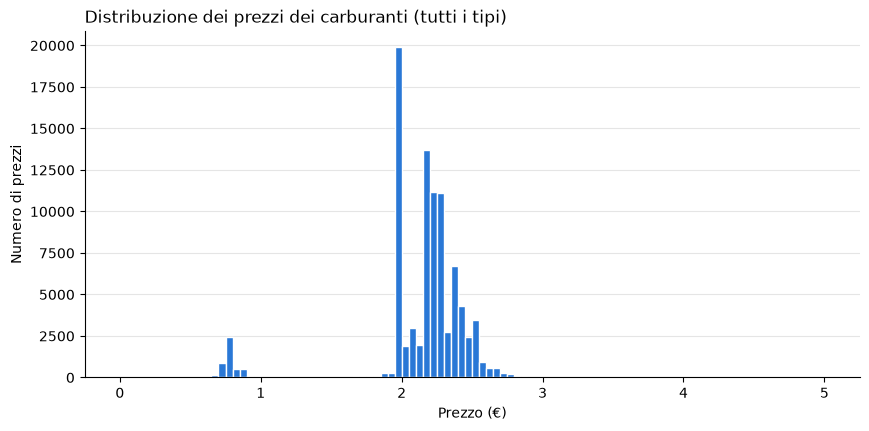

In [8]:
%pip install matplotlib numpy

# Vorrei fare un plot di istogramma della colonna prezzo, anche mischiando i vari carburanti
import matplotlib.pyplot as plt
import numpy as np

# Istogramma di tutti i prezzi, tutti i carburanti insieme (classi da 5 centesimi)
classi = np.arange(0, dati["prezzo"].max() + 0.05, 0.05)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(dati["prezzo"], bins=classi, color="#2a78d6", edgecolor="white", linewidth=1)
ax.set_title("Distribuzione dei prezzi dei carburanti (tutti i tipi)", loc="left")
ax.set_xlabel("Prezzo (€)")
ax.set_ylabel("Numero di prezzi")
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [9]:
# Teniamo solo i prezzi tra 0.50 e 4.00
dati = dati[dati["prezzo"] >= 0.50]
dati = dati[dati["prezzo"] <= 4.00]

## 4: Trovare le storie

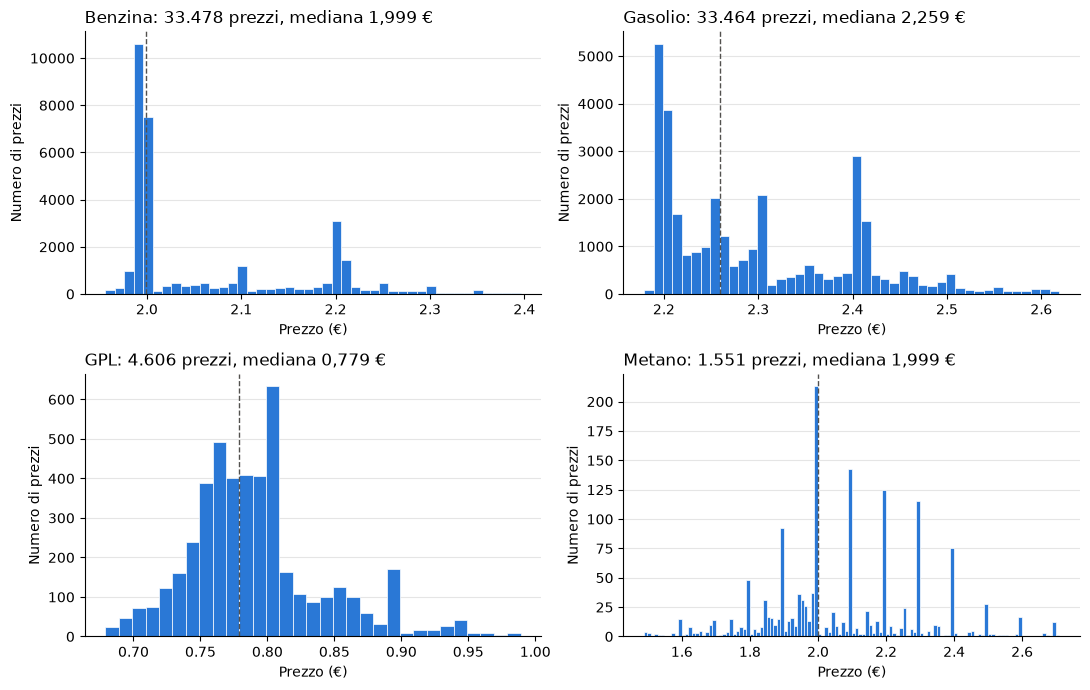

In [10]:
# Ora fai quattro grafici ristretti per: Metano, Benzina, Gasolio, GPL. Ignora le  altre voci.
import matplotlib.pyplot as plt
import numpy as np

carburanti = ["Benzina", "Gasolio", "GPL", "Metano"]

fig, assi = plt.subplots(2, 2, figsize=(11, 7))
for carburante, ax in zip(carburanti, assi.flat):
    p = dati.loc[dati["descCarburante"] == carburante, "prezzo"]
    # Asse x ristretto all'1%-99% dei prezzi, così pochi valori estremi non schiacciano il grafico
    da, a = p.quantile(0.01), p.quantile(0.99)
    classi = np.arange(da - 0.01, a + 0.02, 0.01)  # classi da 1 centesimo
    ax.hist(p, bins=classi, color="#2a78d6", edgecolor="white", linewidth=0.5)
    ax.axvline(p.median(), color="#52514e", linestyle="--", linewidth=1)  # mediana
    n = f"{len(p):,}".replace(",", ".")
    mediana = f"{p.median():.3f}".replace(".", ",")
    ax.set_title(f"{carburante}: {n} prezzi, mediana {mediana} €", loc="left")
    ax.set_xlabel("Prezzo (€)")
    ax.set_ylabel("Numero di prezzi")
    ax.grid(axis="y", color="#e5e5e5")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()


### Analisi dei grafici
- Si vedono bene le "soglie psicologiche"
- Due picchi per benzina e gasolio, corrispondenti probabilmente al prezzo self e servito
- Per il metano è nettissimo lo scatto fra soglie di 10 centesimi

In [11]:
# Aggiungi a dati una colonna "Regione" calcolata sulla base della colonna "Provincia"
# Sigla della provincia -> regione
province_regioni = {
    "Abruzzo": ["AQ", "CH", "PE", "TE"],
    "Basilicata": ["MT", "PZ"],
    "Calabria": ["CS", "CZ", "KR", "RC", "VV"],
    "Campania": ["AV", "BN", "CE", "NA", "SA"],
    "Emilia-Romagna": ["BO", "FC", "FE", "MO", "PC", "PR", "RA", "RE", "RN"],
    "Friuli-Venezia Giulia": ["GO", "PN", "TS", "UD"],
    "Lazio": ["FR", "LT", "RI", "RM", "VT"],
    "Liguria": ["GE", "IM", "SP", "SV"],
    "Lombardia": ["BG", "BS", "CO", "CR", "LC", "LO", "MB", "MI", "MN", "PV", "SO", "VA"],
    "Marche": ["AN", "AP", "FM", "MC", "PU"],
    "Molise": ["CB", "IS"],
    "Piemonte": ["AL", "AT", "BI", "CN", "NO", "TO", "VB", "VC"],
    "Puglia": ["BA", "BR", "BT", "FG", "LE", "TA"],
    "Sardegna": ["CA", "NU", "OR", "SS", "SU"],
    "Sicilia": ["AG", "CL", "CT", "EN", "ME", "PA", "RG", "SR", "TP"],
    "Toscana": ["AR", "FI", "GR", "LI", "LU", "MS", "PI", "PO", "PT", "SI"],
    "Trentino-Alto Adige": ["BZ", "TN"],
    "Umbria": ["PG", "TR"],
    "Valle d'Aosta": ["AO"],
    "Veneto": ["BL", "PD", "RO", "TV", "VE", "VI", "VR"],
}
provincia_a_regione = {sigla: regione for regione, sigle in province_regioni.items() for sigla in sigle}

dati = dati.assign(Regione=dati["Provincia"].map(provincia_a_regione))

# Controllo: nessuna provincia deve restare senza regione
print("Province senza regione:", dati.loc[dati["Regione"].isna(), "Provincia"].unique())
display(dati["Regione"].value_counts())


Province senza regione: <StringArray>
[]
Length: 0, dtype: str


Regione
Lombardia                11819
Lazio                     8502
Veneto                    8139
Campania                  7741
Sicilia                   7556
Emilia-Romagna            7537
Toscana                   6657
Piemonte                  6606
Puglia                    6004
Marche                    3059
Calabria                  2995
Abruzzo                   2583
Sardegna                  2479
Liguria                   1987
Friuli-Venezia Giulia     1856
Umbria                    1788
Trentino-Alto Adige       1732
Basilicata                 985
Molise                     599
Valle d'Aosta              303
Name: count, dtype: int64

descCarburante,Benzina,Gasolio,GPL,Metano
Regione,,,,
Abruzzo,2.069,2.296,0.805,2.022
Basilicata,2.090,2.332,0.785,2.079
Calabria,2.083,2.318,0.834,2.150
Campania,2.076,2.326,0.766,1.939
Emilia-Romagna,2.055,2.288,0.786,2.097
Friuli-Venezia Giulia,2.059,2.290,0.779,2.235
Lazio,2.062,2.290,0.778,2.034
Liguria,2.063,2.283,0.878,2.096
Lombardia,2.048,2.278,0.782,1.978


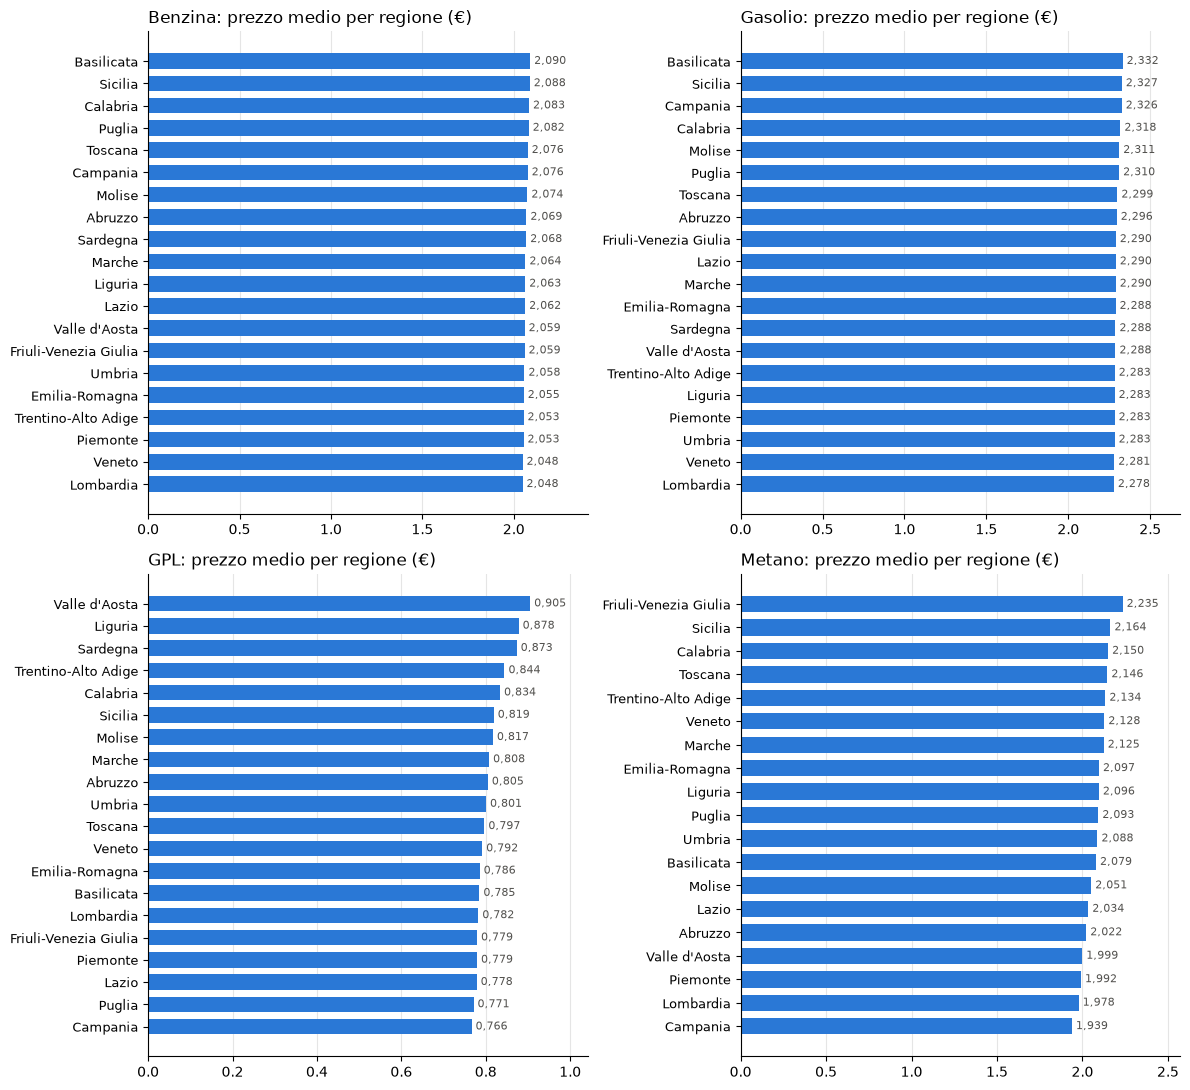

In [12]:
# Per i quattro carburanti scelti, calcola il prezzo medio in ciascuna regione e fai un grafico a barre
# per confrontare i valori, ordinato dalla regione più cara alla meno cara
import matplotlib.pyplot as plt

carburanti = ["Benzina", "Gasolio", "GPL", "Metano"]

# Prezzo medio per regione e carburante (righe = regioni, colonne = carburanti)
medie = (
    dati[dati["descCarburante"].isin(carburanti)]
    .pivot_table(index="Regione", columns="descCarburante", values="prezzo", aggfunc="mean")
    [carburanti]
)
display(medie.round(3))

fig, assi = plt.subplots(2, 2, figsize=(12, 11))
for carburante, ax in zip(carburanti, assi.flat):
    serie = medie[carburante].dropna().sort_values()  # la più cara finisce in alto
    ax.barh(serie.index, serie.values, color="#2a78d6", height=0.7)
    for i, valore in enumerate(serie.values):
        ax.text(valore, i, f" {valore:.3f}".replace(".", ","), va="center", fontsize=8, color="#52514e")
    ax.set_title(f"{carburante}: prezzo medio per regione (€)", loc="left")
    ax.set_xlim(0, serie.max() * 1.15)
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="x", color="#e5e5e5")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()


### Analisi dei grafici
- Notiamo molta uniformità geografica tra benzina e diesel
- Il GPL ha una certa variabilità
- Il metano è influenzato dai pochi distributori (Friuli) e quindi le differenze non sono statisticamente rilevanti
- Questi prezzi sono ancora un mix di self e servito, quindi una regione con più prezzi in modalità servito risulta più cara.

In [13]:
# Per ciascuno dei 4 carburanti mostrami i 5 prezzi più cari e i 4 meno cari
colonne = ["descCarburante", "prezzo", "isSelf", "dtComu", "Bandiera", "Tipo Impianto", "Comune", "Provincia", "Regione"]

for carburante in ["Benzina", "Gasolio", "GPL", "Metano"]:
    p = dati[dati["descCarburante"] == carburante]
    print(f"{carburante}: 5 prezzi più cari")
    display(p.nlargest(5, "prezzo")[colonne])
    print(f"{carburante}: 5 prezzi meno cari")
    display(p.nsmallest(5, "prezzo")[colonne])


Benzina: 5 prezzi più cari


,descCarburante,prezzo,isSelf,dtComu,Bandiera,Tipo Impianto,Comune,Provincia,Regione
79337,Benzina,3.250,0,2026-10-26 10:35:53,Pompe Bianche,Stradale,LAMPEDUSA E LINOSA,AG,Sicilia
19011,Benzina,2.824,0,2026-11-02 07:45:54,Api-Ip,Stradale,PRATO,PO,Toscana
8784,Benzina,2.810,0,2026-11-01 08:18:50,Api-Ip,Stradale,PRIOLA,CN,Piemonte
19262,Benzina,2.810,0,2026-10-30 11:02:38,Api-Ip,Stradale,SALUZZO,CN,Piemonte
19267,Benzina,2.810,0,2026-10-29 08:35:06,Api-Ip,Stradale,MONDOVÌ,CN,Piemonte


Benzina: 5 prezzi meno cari


,descCarburante,prezzo,isSelf,dtComu,Bandiera,Tipo Impianto,Comune,Provincia,Regione
17664,Benzina,1.198,1,2026-10-30 09:07:19,Pompe Bianche,Stradale,COSTA DI MEZZATE,BG,Lombardia
12012,Benzina,1.199,1,2026-10-30 12:39:24,Kerotris,Stradale,PONTECURONE,AL,Piemonte
70911,Benzina,1.199,1,2026-11-02 07:13:55,Api-Ip,Stradale,BELLUNO,BL,Veneto
6338,Benzina,1.206,0,2026-10-28 17:02:23,Agip Eni,Stradale,LIVIGNO,SO,Lombardia
6339,Benzina,1.206,1,2026-10-28 17:02:23,Agip Eni,Stradale,LIVIGNO,SO,Lombardia


Gasolio: 5 prezzi più cari


,descCarburante,prezzo,isSelf,dtComu,Bandiera,Tipo Impianto,Comune,Provincia,Regione
8786,Gasolio,3.175,0,2026-11-01 08:18:50,Api-Ip,Stradale,PRIOLA,CN,Piemonte
19264,Gasolio,3.175,0,2026-10-30 11:02:38,Api-Ip,Stradale,SALUZZO,CN,Piemonte
19269,Gasolio,3.175,0,2026-10-29 08:35:06,Api-Ip,Stradale,MONDOVÌ,CN,Piemonte
20114,Gasolio,3.175,0,2026-10-31 10:54:12,Api-Ip,Stradale,VERZUOLO,CN,Piemonte
21853,Gasolio,3.175,0,2026-10-29 11:47:51,Api-Ip,Stradale,VILLANOVA MONDOVÌ,CN,Piemonte


... (6 outputs left out)

Metano: 5 prezzi più cari


,descCarburante,prezzo,isSelf,dtComu,Bandiera,Tipo Impianto,Comune,Provincia,Regione
12693,Metano,2.999,0,2026-10-30 18:04:11,ValliCarburanti,Stradale,CODEVIGO,PD,Veneto
61118,Metano,2.999,0,2026-10-29 05:11:19,DBCarburanti,Stradale,CEFALÙ,PA,Sicilia
79935,Metano,2.857,0,2026-10-30 12:07:48,Pompe Bianche,Stradale,RIPOSTO,CT,Sicilia
50150,Metano,2.809,0,2026-10-30 22:25:14,Edison metano,Stradale,MARSALA,TP,Sicilia
81708,Metano,2.809,0,2026-10-30 22:26:03,Adamo Idrocarburi,Stradale,MAZARA DEL VALLO,TP,Sicilia


Metano: 5 prezzi meno cari


,descCarburante,prezzo,isSelf,dtComu,Bandiera,Tipo Impianto,Comune,Provincia,Regione
77582,Metano,1.000,0,2026-10-26 07:54:57,Pompe Bianche,Stradale,RESUTTANO,CL,Sicilia
14654,Metano,1.240,0,2026-11-02 06:50:08,Agip Eni,Stradale,TORRE SANTA SUSANNA,BR,Puglia
63738,Metano,1.315,1,2026-10-30 14:42:48,Bianco Carburanti,Stradale,VILLASANTA,MB,Lombardia
19261,Metano,1.350,0,2026-10-27 10:57:13,Pompe Bianche,Stradale,MORTARA,PV,Lombardia
39391,Metano,1.359,0,2026-10-28 13:13:31,Energas,Stradale,TERZIGNO,NA,Campania


## 5: Visualizzare i dati
- Esportiamo il lavoro fatto finora come file Excel
- Non dovremo necessariamente aprirlo con Excel, ma solo importarlo in strumenti di visualizzazione
- Mappe possibili con [DataWrapper](DataWrapper.de) (qui scegliamo il metano perché ha meno distributori e le visualizzazioni sono più veloci):
  - Mappa di punti con tutti i distributori di metano
  - Mappa per regione con il numero di distributori (numero assoluto, non scalato in base alla popolazione)
  - Mappa per regione con il prezzo medio del metano
- Per la benzina possiamo invece fare una mappa che mostri, a livello di provincia, il risparmio possibile per la benzina in modalità self all'interno della provincia

In [14]:
# Produci un file Excel con l'esportazione della tabella dati
# Esportiamo in Excel.
%pip install openpyxl
dati.to_excel(
    "dati_prezzi_carburanti.xlsx",
    sheet_name="Prezzi",
    index=False,                 # niente colonna con l'indice di pandas
    freeze_panes=(1, 0),         # intestazione bloccata quando scorri
)

Note: you may need to restart the kernel to use updated packages.


In [15]:
# Dal file anagrafica estrai i distributori di metano ed esporta in Excel
# Impianti che hanno almeno un prezzo per il metano
id_metano = prezzi.loc[prezzi["descCarburante"] == "Metano", "idImpianto"].unique()

distributori_metano = anagrafica[anagrafica["idImpianto"].isin(id_metano)]

print(len(distributori_metano), "distributori di metano")

distributori_metano.to_excel(
    "distributori_metano.xlsx",
    sheet_name="Metano",
    index=False,
    freeze_panes=(1, 0),
)


1499 distributori di metano


In [16]:
# Esporta in Excel i dati del solo metano
prezzi_metano = dati[dati["descCarburante"] == "Metano"]
prezzi_metano = prezzi_metano[prezzi_metano["prezzo"].between(1.2, 3.5)]

print(len(prezzi_metano), "prezzi del metano")

prezzi_metano.to_excel(
    "prezzi_metano.xlsx",
    sheet_name="Metano",
    index=False,
    freeze_panes=(1, 0),
)


1550 prezzi del metano


In [17]:
# Esporta in Excel una tabella con una riga per regione (escluse quelle che
# non hanno metano) con le colonne: Regione,
# NumDistributori (numero distributori di metano in quella regione),
# PrezzoMedio (prezzo medio del metano in quella regione)
# Prezzi del metano, senza i valori anomali (stessa soglia usata per prezzi_metano)
metano = dati[(dati["descCarburante"] == "Metano") & dati["prezzo"].between(1.2, 3.5)]

metano_regioni = (
    metano.groupby("Regione")
    .agg(NumDistributori=("idImpianto", "nunique"), PrezzoMedio=("prezzo", "mean"))
    .round({"PrezzoMedio": 3})
    .sort_values("PrezzoMedio", ascending=False)
    .reset_index()
)
display(metano_regioni)

metano_regioni.to_excel(
    "metano_per_regione.xlsx",
    sheet_name="Metano per regione",
    index=False,
    freeze_panes=(1, 0),
)


,Regione,NumDistributori,PrezzoMedio
0,Friuli-Venezia Giulia,10,2.235
1,Sicilia,47,2.189
2,Calabria,21,2.150
3,Toscana,157,2.146
4,Trentino-Alto Adige,17,2.134
5,Veneto,166,2.128
6,Marche,103,2.125
7,Emilia-Romagna,227,2.097
8,Liguria,11,2.096
9,Puglia,111,2.093


In [18]:
# Ora fai una tabella in cui mostriamo quanto si può risparmiare sulla benzina all'interno di ciascuna provincia.
# Usiamo solo i prezzi della benzina e solo self (isSelf = 1).
# Per ciascuna provincia la tabella avrà:
# - Una colonna "NomeProvincia" con il nome della provincia, ad esempio se Provincia è AL allora NomeProvincia è Alessandria
# - Una colonna "Minimo" con il prezzo più basso all'interno della provincia
# - Una colonna "Massimo" con il prezzo più alto all'interno della provincia
# - Una colonna "Risparmio" con Massimo - Minimo
# Sigla della provincia -> nome
nomi_province = {
    "AG": "Agrigento", "AL": "Alessandria", "AN": "Ancona", "AO": "Aosta", "AP": "Ascoli Piceno",
    "AQ": "L'Aquila", "AR": "Arezzo", "AT": "Asti", "AV": "Avellino", "BA": "Bari",
    "BG": "Bergamo", "BI": "Biella", "BL": "Belluno", "BN": "Benevento", "BO": "Bologna",
    "BR": "Brindisi", "BS": "Brescia", "BT": "Barletta-Andria-Trani", "BZ": "Bolzano", "CA": "Cagliari",
    "CB": "Campobasso", "CE": "Caserta", "CH": "Chieti", "CL": "Caltanissetta", "CN": "Cuneo",
    "CO": "Como", "CR": "Cremona", "CS": "Cosenza", "CT": "Catania", "CZ": "Catanzaro",
    "EN": "Enna", "FC": "Forlì-Cesena", "FE": "Ferrara", "FG": "Foggia", "FI": "Firenze",
    "FM": "Fermo", "FR": "Frosinone", "GE": "Genova", "GO": "Gorizia", "GR": "Grosseto",
    "IM": "Imperia", "IS": "Isernia", "KR": "Crotone", "LC": "Lecco", "LE": "Lecce",
    "LI": "Livorno", "LO": "Lodi", "LT": "Latina", "LU": "Lucca", "MB": "Monza e della Brianza",
    "MC": "Macerata", "ME": "Messina", "MI": "Milano", "MN": "Mantova", "MO": "Modena",
    "MS": "Massa-Carrara", "MT": "Matera", "NA": "Napoli", "NO": "Novara", "NU": "Nuoro",
    "OR": "Oristano", "PA": "Palermo", "PC": "Piacenza", "PD": "Padova", "PE": "Pescara",
    "PG": "Perugia", "PI": "Pisa", "PN": "Pordenone", "PO": "Prato", "PR": "Parma",
    "PT": "Pistoia", "PU": "Pesaro e Urbino", "PV": "Pavia", "PZ": "Potenza", "RA": "Ravenna",
    "RC": "Reggio Calabria", "RE": "Reggio Emilia", "RG": "Ragusa", "RI": "Rieti", "RM": "Roma",
    "RN": "Rimini", "RO": "Rovigo", "SA": "Salerno", "SI": "Siena", "SO": "Sondrio",
    "SP": "La Spezia", "SR": "Siracusa", "SS": "Sassari", "SU": "Sud Sardegna", "SV": "Savona",
    "TA": "Taranto", "TE": "Teramo", "TN": "Trento", "TO": "Torino", "TP": "Trapani",
    "TR": "Terni", "TS": "Trieste", "TV": "Treviso", "UD": "Udine", "VA": "Varese",
    "VB": "Verbano-Cusio-Ossola", "VC": "Vercelli", "VE": "Venezia", "VI": "Vicenza", "VR": "Verona",
    "VT": "Viterbo", "VV": "Vibo Valentia",
}

benzina_self = dati[(dati["descCarburante"] == "Benzina") & (dati["isSelf"] == 1)]

risparmio_province = (
    benzina_self.groupby("Provincia")["prezzo"]
    .agg(Minimo="min", Massimo="max")
    .reset_index()
)
risparmio_province["NomeProvincia"] = risparmio_province["Provincia"].map(nomi_province)
risparmio_province["Risparmio"] = (risparmio_province["Massimo"] - risparmio_province["Minimo"]).round(3)
risparmio_province = (
    risparmio_province[["NomeProvincia", "Minimo", "Massimo", "Risparmio"]]
    .sort_values("Risparmio", ascending=False)
    .reset_index(drop=True)
)

# Controllo: nessuna sigla deve restare senza nome
print("Province senza nome:", risparmio_province["NomeProvincia"].isna().sum())
display(risparmio_province)


Province senza nome: 0


,NomeProvincia,Minimo,Massimo,Risparmio
0,Sondrio,1.206,2.290,1.084
1,Bergamo,1.198,2.269,1.071
2,Foggia,1.729,2.799,1.070
3,Perugia,1.719,2.789,1.070
4,Napoli,1.659,2.629,0.970
...,...,...,...,...
102,Lodi,1.959,2.105,0.146
103,Gorizia,1.987,2.119,0.132
104,Massa-Carrara,1.979,2.099,0.120
105,Cagliari,1.979,2.089,0.110


In [19]:
# Per eliminare i casi limite, fai la stessa cosa confrontando il 5% di prezzi più bassi
# con il 5% di prezzi più alti. Esporta il risultato in Excel.
risparmio_province_5 = (
    benzina_self.groupby("Provincia")["prezzo"]
    .agg(
        NumPrezzi="count",
        Basso5=lambda p: p.quantile(0.05),   # il 5% dei prezzi è sotto questo valore
        Alto95=lambda p: p.quantile(0.95),   # il 5% dei prezzi è sopra questo valore
    )
    .reset_index()
)
risparmio_province_5["NomeProvincia"] = risparmio_province_5["Provincia"].map(nomi_province)
risparmio_province_5["Risparmio"] = risparmio_province_5["Alto95"] - risparmio_province_5["Basso5"]
risparmio_province_5 = (
    risparmio_province_5[["NomeProvincia", "NumPrezzi", "Basso5", "Alto95", "Risparmio"]]
    .round({"Basso5": 3, "Alto95": 3, "Risparmio": 3})
    .sort_values("Risparmio", ascending=False)
    .reset_index(drop=True)
)
display(risparmio_province_5)

risparmio_province_5.to_excel(
    "risparmio_benzina_self_province.xlsx",
    sheet_name="Risparmio benzina self",
    index=False,
    freeze_panes=(1, 0),
)


,NomeProvincia,NumPrezzi,Basso5,Alto95,Risparmio
0,Sondrio,61,1.608,2.095,0.487
1,Trieste,32,1.990,2.295,0.305
2,Foggia,187,1.969,2.198,0.229
3,Salerno,340,1.979,2.199,0.220
4,Rieti,79,1.979,2.199,0.220
...,...,...,...,...,...
102,Lecco,83,1.961,1.999,0.038
103,Lodi,71,1.986,2.014,0.028
104,Biella,69,1.981,1.999,0.018
105,Cagliari,127,1.989,1.999,0.010
